In [614]:
import pandas as pd
import numpy as np

In [615]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"
df = pd.read_csv(url)
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [616]:
df = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]

In [617]:
df['fuel_efficiency_mpg'].tail(50)

,fuel_efficiency_mpg
9950,33.5
9951,30.7
9952,31.7
9953,30.2
9954,30.4
9955,26.8
9956,30.3
9957,30.2
9958,34.9
9959,30.6


In [618]:
df.columns[df.isnull().any()]

Index(['horsepower'], dtype='object')

In [619]:
df['horsepower'].median()

254.0

In [620]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

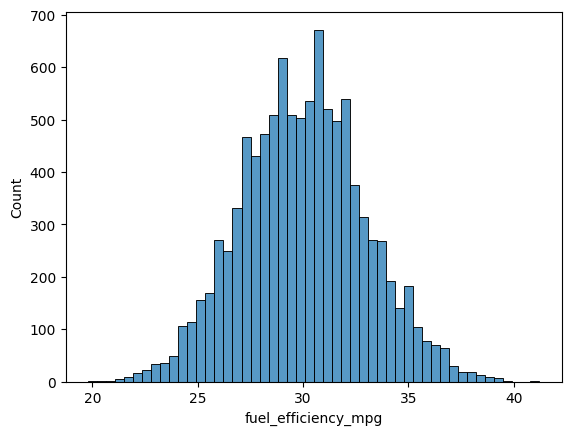

In [621]:
sns.histplot(df.fuel_efficiency_mpg, bins=50)

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

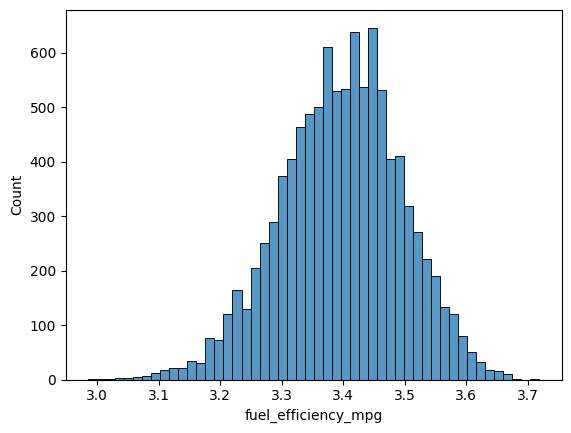

In [622]:
fuel_logs = np.log(df.fuel_efficiency_mpg)
sns.histplot(fuel_logs, bins=50)

In [623]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

n_val, n_test, n_train

(2000, 2000, 6000)

In [624]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [625]:
len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

In [626]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [627]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [628]:
y_train

array([32.5, 29.1, 34.1, ..., 27.7, 31.6, 28. ])

In [629]:
def train_linear_regression(X, y):
  ones = np.ones(X.shape[0])
  X = np.column_stack([ones, X])

  XTX = X.T.dot(X)
  XTX_inv = np.linalg.inv(XTX)
  w_full = XTX_inv.dot(X.T).dot(y)

  return w_full[0], w_full[1:]

In [630]:
base = list(df_train.columns)
base

['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

In [631]:
df_train[base].isnull().sum()

,0
engine_displacement,0
horsepower,538
vehicle_weight,0
model_year,0


Заполнение пропущенных значений 0

In [632]:
X_train = df_train[base].fillna(0).values

In [633]:
w0, w = train_linear_regression(X_train, y_train)
w0, w

(np.float64(-153.8849618823138),
 array([-1.51505520e-03, -4.74024794e-06, -3.95418397e-03,  1.02146785e-01]))

In [634]:
y_pred = w0 + X_train.dot(w)
y_pred

array([34.07471478, 29.24093577, 32.95179055, ..., 29.32203017,
       31.8448482 , 29.69112172])

<Axes: ylabel='Count'>

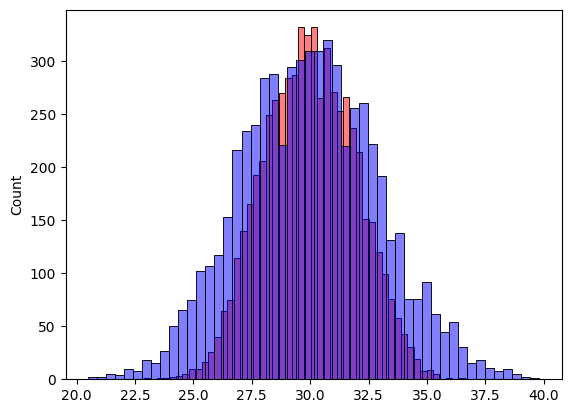

In [635]:
sns.histplot(y_pred, bins=50, alpha=0.5, color='red')
sns.histplot(y_train, bins=50, alpha=0.5, color='blue')

In [636]:
def rmse(y, y_pred):
  error = y - y_pred
  mse = (error ** 2).mean()
  return np.sqrt(mse)

RMSE с fillna(0)

In [637]:
score = rmse(y_train, y_pred)
round(score, 3)

np.float64(2.2)

Заполнение пропущенных значений mean



In [638]:
X_train = df_train[base].fillna(df_train.horsepower.mean()).values

In [639]:
w0, w = train_linear_regression(X_train, y_train)
w0, w

(np.float64(-153.29645639114293),
 array([-0.00102386, -0.00648622, -0.00388828,  0.10197897]))

In [640]:
y_pred = w0 + X_train.dot(w)
y_pred

array([33.9590606 , 29.31436861, 32.76131994, ..., 29.30040609,
       31.92376266, 29.67268373])

<Axes: ylabel='Count'>

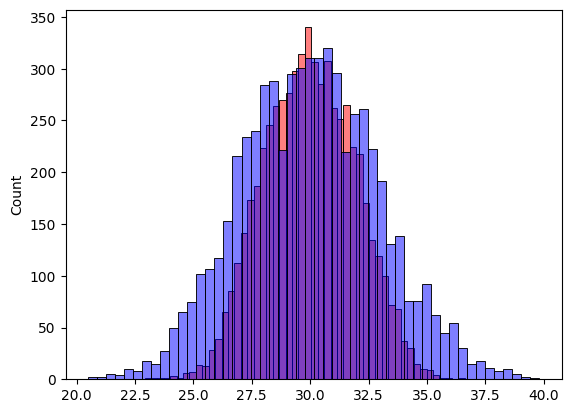

In [641]:
sns.histplot(y_pred, bins=50, alpha=0.5, color='red')
sns.histplot(y_train, bins=50, alpha=0.5, color='blue')

In [642]:
score = rmse(y_train, y_pred)
round(score, 3)

np.float64(2.198)

In [643]:
def prepare_X(df, fill=0):
  df = df.copy()
  features = base.copy()

  X_filled = df[features].fillna(fill)

  return X_filled.values

Тренировка регрессии **С РЕГУЛЯРИЗАЦИЕЙ**

In [644]:
def train_linear_regression_reg(X, y, reg=0):
  ones = np.ones(X.shape[0])
  X = np.column_stack([ones, X])

  XTX = X.T.dot(X)

  #reg
  XTX = XTX + reg * np.eye(XTX.shape[0])

  XTX_inv = np.linalg.inv(XTX)
  w_full = XTX_inv.dot(X.T).dot(y)

  return w_full[0], w_full[1:]

Заполнение пропущенных значений 0

In [645]:
X_train = prepare_X(df_train)

In [646]:
w0, w = train_linear_regression_reg(X_train, y_train, reg=5)
w0, w

(np.float64(-7.7728522099734025),
 array([-0.00221541,  0.0046495 , -0.00430467,  0.03008084]))

In [647]:
X_val = prepare_X(df_val)

In [648]:
y_pred = w0 + X_val.dot(w)
y_pred

array([31.60312535, 28.33648923, 30.33786763, ..., 29.24660163,
       29.66980724, 30.22313794])

In [649]:
score = rmse(y_val, y_pred)
round(score, 5)

np.float64(2.40938)

In [650]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
  w0, w = train_linear_regression_reg(X_train, y_train, reg=r)

  y_pred = w0 + X_val.dot(w)
  score = rmse(y_val, y_pred)
  print(f'reg = {r} | {round(score, 5)}')

reg = 0 | 2.20529
reg = 0.01 | 2.20583
reg = 0.1 | 2.22414
reg = 1 | 2.34923
reg = 5 | 2.40938
reg = 10 | 2.41947
reg = 100 | 2.4292


**Задание 5**

In [651]:
scores = []

for seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
  n = len(df)
  n_val = int(n * 0.2)
  n_test = int(n * 0.2)
  n_train = n - n_val - n_test

  np.random.seed(seed)
  idx = np.arange(n)
  np.random.shuffle(idx)

  df_train = df.iloc[idx[:n_train]]
  df_val = df.iloc[idx[n_train:n_train + n_val]]
  df_test = df.iloc[idx[n_train + n_val:]]

  #---

  df_train = df_train.reset_index(drop=True)
  df_val = df_val.reset_index(drop=True)
  df_test = df_test.reset_index(drop=True)

  y_train = df_train.fuel_efficiency_mpg.values
  y_val = df_val.fuel_efficiency_mpg.values
  y_test = df_test.fuel_efficiency_mpg.values

  del df_train['fuel_efficiency_mpg']
  del df_val['fuel_efficiency_mpg']
  del df_test['fuel_efficiency_mpg']

  #---

  X_train = prepare_X(df_train)
  X_val = prepare_X(df_val)

  w0, w = train_linear_regression(X_train, y_train)

  y_pred = w0 + X_val.dot(w)
  score = rmse(y_val, y_pred)

  scores.append(score)

In [652]:
scores_std = np.std(scores)
round(scores_std, 3)

np.float64(0.029)

**Задание 6**

In [653]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

#---

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

df_train = pd.concat([df_train, df_val])

y_train = df_train.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

#---

X_train = prepare_X(df_train)
X_test = prepare_X(df_test)

w0, w = train_linear_regression_reg(X_train, y_train, reg=0.001)

y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)

round(score, 3)

np.float64(2.236)